In [8]:
!pip install -q -U transformers accelerate gdown pandas pillow tqdm
!pip install -q git+https://github.com/huggingface/transformers
!pip install -q qwen-vl-utils
!apt-get update -qq
!apt-get install -y -qq default-jre-headless libxml-parser-perl

!pip install -q git+https://github.com/bckim92/language-evaluation.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libperl5.38t64_5.38.2-3.2ubuntu0.7_amd64.deb ...
Unpacking libperl5.38t64:amd64 (5.38.2-3.2ubuntu0.7) over (5.38.2-3.2ubuntu0.2) ...
Preparing to unpack .../perl_5.38.2-3.2ubuntu0.7_amd64.deb ...
Unpacking perl (5.38.2-3.2ubuntu0.7) over (5.38.2-3.2ubuntu0.2) ...
Preparing to unpack .../perl-base_5.38.2-3.2ubuntu0.7_amd64.deb ...
Unpacking perl-base (5.38.2-3.2ubuntu0.7) over (5.38.2-3.2ubuntu0.2) ...
Setting up perl-base (5.38.2-3.2ubuntu0.7) ...
(Reading database ... 127324 files and directories currently installed.)
Preparing to 

In [9]:
import os
import json
import zipfile
import shutil
import subprocess
import random
import time

from pathlib import Path

import torch
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("/content/artcap")
DOWNLOAD_DIR = Path("/content/artcap_download")
KALE_DIR = Path("/content/kale_data")

OUTPUT_DIR = Path("/content/drive/MyDrive/EMMbedding")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_DIR.mkdir(parents=True, exist_ok=True)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
KALE_DIR.mkdir(parents=True, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
    "GB"
)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


GPU: NVIDIA L4
GPU memory: 23.66 GB


In [10]:
!gdown --folder "https://drive.google.com/drive/folders/1l8NK8mvpkG3UfrTuTNyBZciIjFquV2ia" -O /content/artcap_download

Using cookies from /root/.cache/gdown/cookies.txt
Retrieving folder contents
Processing file 1562bgaAoI6t6-HBsvsp5O6NJ3ATiqOIV ArtCap.json
Processing file 1inQ4W-CtNhhfo1vAehSbLgyMPTmltWVa images.zip
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1562bgaAoI6t6-HBsvsp5O6NJ3ATiqOIV
To: /content/artcap_download/ArtCap.json

Downloading...
From (original): https://drive.google.com/uc?id=1inQ4W-CtNhhfo1vAehSbLgyMPTmltWVa
From (redirected): https://drive.google.com/uc?id=1inQ4W-CtNhhfo1vAehSbLgyMPTmltWVa&confirm=t&uuid=2f26b387-788c-4ba5-8d20-f10dfb7d399c
To: /content/artcap_download/images.zip

Download completed


In [11]:
for zip_path in DOWNLOAD_DIR.rglob("*.zip"):

    print("Extracting:", zip_path.name)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(DATA_DIR)

print("Extraction complete!")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

image_paths = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("Total images:", len(image_paths))

assert len(image_paths) == 3606, (
    f"Expected 3606 images, found {len(image_paths)}"
)

Extracting: images.zip
Extraction complete!
Total images: 3606


In [12]:
!gdown --folder "https://drive.google.com/drive/folders/1m-STuGx1U7c8tQ_KkqOv39CGaFTAs6WY" -O /content/kale_shared

Using cookies from /root/.cache/gdown/cookies.txt
Retrieving folder contents
Retrieving folder 1nlpM6wzq9UnJVk-3kW9QKIW7ohgovd5I bert_base_uncased
Processing file 1MS60BYi3l2UPY0aP6B4V-iN5zYnFxlOe config.json
Processing file 113uJiG15sjPD2i3yxdUqKInU5aQOU5nm pytorch_model.bin
Processing file 1TuHCd1_wsoF4bm_5KsMMAuwLaK7WyfXa tokenizer.json
Processing file 1HCkajvQbDHgI4ox_Y7KPFRyVnjKBXzs4 tokenizer_config.json
Processing file 1WGa3VxGth8iyCmhEt6IfRUEGWiz9ysya vocab.txt
Processing file 1OdPZMQQACgy2OmRsIp3-W-KnD7ATC-hO data.zip
Processing file 1911bA-ua6P6Nxg3-supaPWEFNKZ0Ns-_ graph.pkl
Processing file 1zO4MgxnmqxMFDvLc5W9ZRg82uhXPvAFc language_evaluation.zip
Processing file 18xguRwvnGt8kZyApGvB3tUQxw7l4j33c ViT-L-14.tar
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1MS60BYi3l2UPY0aP6B4V-iN5zYnFxlOe
To: /content/kale_shared/bert_base_uncased/config.json

Downloading...
From (or

In [13]:
kale_zip_files = list(Path("/content/kale_shared").rglob("data.zip"))

if not kale_zip_files:
    raise FileNotFoundError(
        "Could not find data.zip in the downloaded KALE resources. "
        "Inspect /content/kale_shared."
    )

KALE_ANNOTATION_ZIP = kale_zip_files[0]

print("Found:", KALE_ANNOTATION_ZIP)

with zipfile.ZipFile(KALE_ANNOTATION_ZIP, "r") as z:

    annotation_files = [
        name for name in z.namelist()
        if Path(name).name in [
            "artcap_test.json",
            "artcap_train_val.json"
        ]
    ]

    print("Annotation files:", annotation_files)

    for name in annotation_files:
        destination = KALE_DIR / Path(name).name

        with z.open(name) as source, open(destination, "wb") as target:
            shutil.copyfileobj(source, target)

print("Annotation extraction complete!")

Found: /content/kale_shared/data.zip
Annotation files: ['data/ArtCap/artcap_test.json', 'data/ArtCap/artcap_train_val.json']
Annotation extraction complete!


In [14]:
TEST_ANN_PATH = KALE_DIR / "artcap_test.json"

assert TEST_ANN_PATH.exists(), "Missing artcap_test.json"

with open(TEST_ANN_PATH, "r") as f:
    test_annotations = json.load(f)

print("Test annotation count:", len(test_annotations))
print("Example:", test_annotations[0])

Test annotation count: 1082
Example: ['34256.jpg', ['a painter was copying a model sleeping with a book in her arms', 'a woman looking at a book in front of a mirror', 'a girl with a man reading at a drawing table', 'a painter is sitting in a chair painting', 'an artist is drawing a woman reading a book']]


In [15]:
# Index all downloaded images by filename
image_by_name = {
    p.name: p
    for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
}

test_data = []

for record in test_annotations:

    filename = record[0]
    captions = record[1]

    image_name = Path(filename).name
    image_id = Path(filename).stem

    if image_name not in image_by_name:
        raise FileNotFoundError(
            f"Image not found: {image_name}"
        )

    if len(captions) != 5:
        raise ValueError(
            f"{image_id} has {len(captions)} captions instead of 5"
        )

    test_data.append({
        "image_id": image_id,
        "image_path": image_by_name[image_name],
        "references": captions
    })

test_df = pd.DataFrame(test_data)

print("Official test images:", len(test_df))
print("Total human captions:", sum(len(x) for x in test_df["references"]))

display(test_df.head())

Official test images: 1082
Total human captions: 5410


,image_id,image_path,references
0,34256,/content/artcap/images/34256.jpg,[a painter was copying a model sleeping with a...
1,36291,/content/artcap/images/36291.jpg,"[a woman is sitting at the beach, a woman is g..."
2,77815,/content/artcap/images/77815.jpg,[a woman with an orange umbrella sits on a gra...
3,81324,/content/artcap/images/81324.jpg,"[a woman is holding a lion on the stage, a wom..."
4,53572,/content/artcap/images/53572.jpg,[cascading shot of several men in shorts runni...


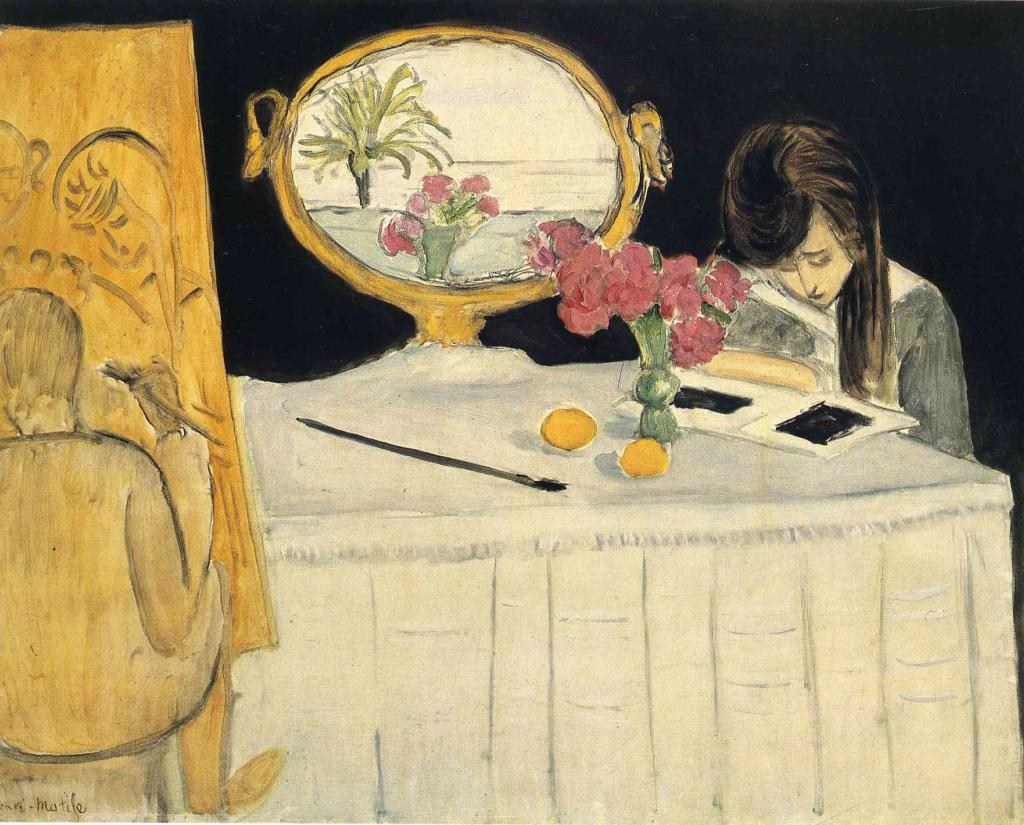

Image ID: 34256

Human reference captions:
1. a painter was copying a model sleeping with a book in her arms
2. a woman looking at a book in front of a mirror
3. a girl with a man reading at a drawing table
4. a painter is sitting in a chair painting
5. an artist is drawing a woman reading a book


In [16]:
sample = test_df.iloc[0]

display(Image.open(sample["image_path"]))

print("Image ID:", sample["image_id"])
print("\nHuman reference captions:")

for i, caption in enumerate(sample["references"], 1):
    print(f"{i}. {caption}")

In [17]:
from transformers import (
    AutoProcessor,
    Qwen3VLForConditionalGeneration
)

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=224 * 224,
    max_pixels=768 * 768
)

model.eval()

print("Loaded:", MODEL_ID)
print("Device:", model.device)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Loaded: Qwen/Qwen3-VL-4B-Instruct
Device: cuda:0


In [18]:
PROMPT = """
Describe the visual content of this painting in one concise,
informative sentence.

Focus on:
- The people, objects, and subjects depicted.
- Their actions and spatial relationships.
- Important colors, visual attributes, and setting.

Only describe details that are visually supported by the image.
Do not speculate about the artist, historical context, or
symbolic meaning.

Return only the caption.
"""

In [19]:
def generate_caption(image_path):

    image = Image.open(image_path).convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image
                },
                {
                    "type": "text",
                    "text": PROMPT
                }
            ]
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=128,
            do_sample=False
        )

    # Remove input tokens
    generated_ids = generated_ids[:, inputs.input_ids.shape[1]:]

    caption = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0].strip()

    return caption

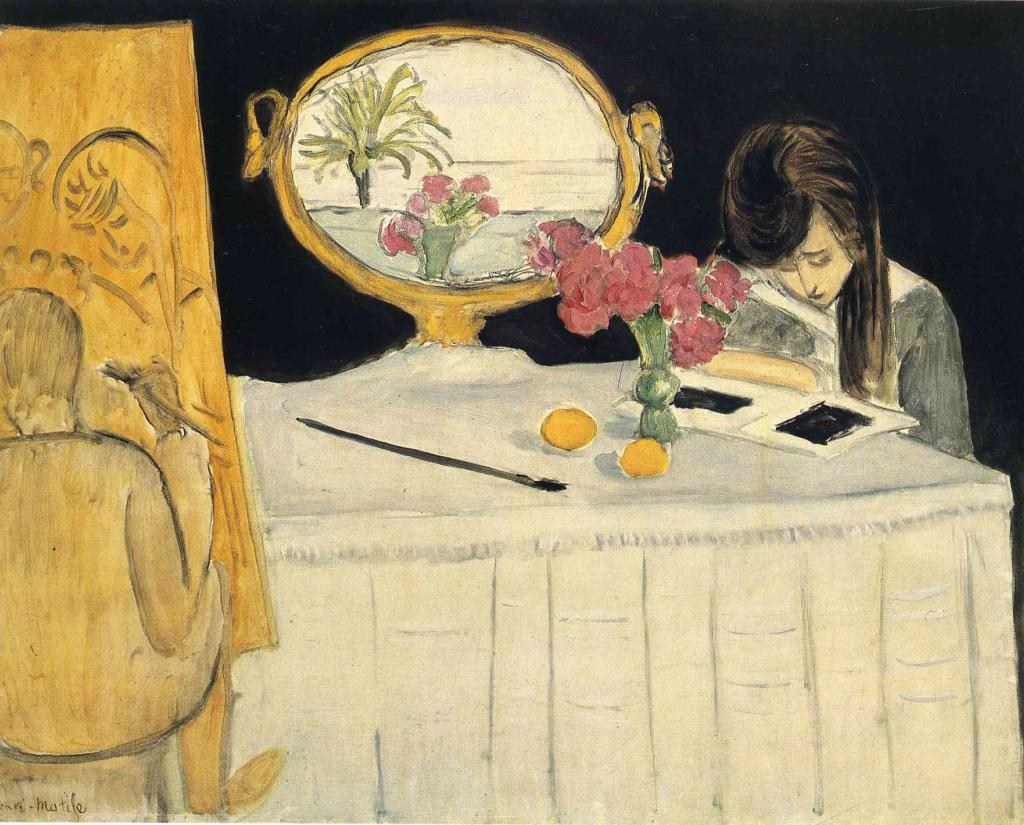

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Qwen3-VL generated caption:
A woman with dark hair sits at a white-clothed table, looking down at a book or paper, while a round mirror reflects a palm tree and flowers, and a vase of pink flowers, two lemons, and a brush rest on the table beside her, with a carved wooden chair to the left.


In [20]:
sample_path = test_df.iloc[0]["image_path"]

display(Image.open(sample_path))

sample_caption = generate_caption(sample_path)

print("Qwen3-VL generated caption:")
print(sample_caption)

In [21]:
PREDICTION_PATH = OUTPUT_DIR / "qwen3_vl_baseline_predictions.csv"

# Resume if predictions already exist
if PREDICTION_PATH.exists():

    previous_df = pd.read_csv(PREDICTION_PATH)

    prediction_lookup = dict(
        zip(
            previous_df["image_id"].astype(str),
            previous_df["pred_caption"]
        )
    )

else:
    prediction_lookup = {}

print("Existing predictions:", len(prediction_lookup))

for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):

    image_id = str(row["image_id"])

    # Skip images already processed
    if image_id in prediction_lookup:
        continue

    try:
        caption = generate_caption(row["image_path"])
        prediction_lookup[image_id] = caption

    except Exception as e:
        print(f"Error on {image_id}: {e}")

    # Save progress periodically
    if (idx + 1) % 25 == 0:

        progress_df = pd.DataFrame([
            {
                "image_id": key,
                "pred_caption": value
            }
            for key, value in prediction_lookup.items()
        ])

        progress_df.to_csv(PREDICTION_PATH, index=False)

# Final save
results_df = pd.DataFrame([
    {
        "image_id": str(row["image_id"]),
        "image_path": str(row["image_path"]),
        "pred_caption": prediction_lookup[str(row["image_id"])]
    }
    for _, row in test_df.iterrows()
    if str(row["image_id"]) in prediction_lookup
])

results_df.to_csv(PREDICTION_PATH, index=False)

print("\nPredictions generated:", len(results_df))
print("Expected:", len(test_df))
display(results_df.head())

Existing predictions: 0


  0%|          | 0/1082 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
/usr/local/lib/python3.13


Predictions generated: 1082
Expected: 1082


,image_id,image_path,pred_caption
0,34256,/content/artcap/images/34256.jpg,A woman with dark hair sits at a white-clothed...
1,36291,/content/artcap/images/36291.jpg,A sunlit beach scene viewed from under a canop...
2,77815,/content/artcap/images/77815.jpg,A woman in a pink blouse and blue skirt sits i...
3,81324,/content/artcap/images/81324.jpg,A nude woman with red hair and black stockings...
4,53572,/content/artcap/images/53572.jpg,"A vibrant, abstract painting depicts multiple ..."


In [23]:
from google.colab import drive

# drive.mount("/content/drive")

OUTPUT_DIR = Path("/content/drive/MyDrive/EMMbedding")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# !apt-get update -qq
# !apt-get install -y -qq default-jre-headless libxml-parser-perl

# !pip install -q git+https://github.com/bckim92/language-evaluation.git

In [32]:
import language_evaluation

print("Java version:")
!java -version

language_evaluation.download("coco")

evaluator = language_evaluation.CocoEvaluator(
    verbose=True
)

print("Evaluator ready!")

Java version:
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
/usr/local/lib/python3.13/dist-packages/language_evaluation/coco_caption_py3/pycocoevalcap/meteor/data/paraphrase-en.gz already exists
Evaluator ready!


In [33]:
# Create prediction lookup
prediction_lookup = dict(
    zip(
        results_df["image_id"].astype(str),
        results_df["pred_caption"]
    )
)

predictions = []
answers = []

for _, row in test_df.iterrows():

    image_id = str(row["image_id"])

    if image_id not in prediction_lookup:
        raise ValueError(f"Missing prediction for {image_id}")

    predictions.append(prediction_lookup[image_id])

    # Five human-written reference captions
    answers.append(row["references"])

# Validate
assert len(predictions) == len(test_df)
assert len(answers) == len(test_df)
assert all(len(refs) == 5 for refs in answers)

print("Number of predictions:", len(predictions))
print("Number of reference sets:", len(answers))
print("Total reference captions:", sum(len(x) for x in answers))

Number of predictions: 1082
Number of reference sets: 1082
Total reference captions: 5410


In [87]:
!pip install -q bert-score

In [89]:

import os
import json
import time
import torch
import pandas as pd
import numpy as np

from pathlib import Path
from tqdm.auto import tqdm
from PIL import Image

# ============================================================
# 1. IMPORT METRIC IMPLEMENTATIONS
# ============================================================

from language_evaluation.coco_caption_py3.pycocoevalcap.tokenizer.ptbtokenizer import PTBTokenizer

from language_evaluation.coco_caption_py3.pycocoevalcap.bleu.bleu import Bleu
from language_evaluation.coco_caption_py3.pycocoevalcap.meteor.meteor import Meteor
from language_evaluation.coco_caption_py3.pycocoevalcap.rouge.rouge import Rouge
from language_evaluation.coco_caption_py3.pycocoevalcap.cider.cider import Cider

from bert_score import score as bertscore_score

# ============================================================
# 2. VALIDATE DATA
# ============================================================

assert len(predictions) == len(answers)
assert all(len(refs) == 5 for refs in answers)
assert len(test_df) == len(predictions)

print("Predictions:", len(predictions))
print("Reference sets:", len(answers))
print("Total references:", sum(len(x) for x in answers))

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Evaluation device:", device)

# ============================================================
# 3. CONSTRUCT COCO-STYLE INPUTS
# ============================================================

gts_raw = {}
res_raw = {}

for i, (prediction, references) in enumerate(
    zip(predictions, answers)
):

    gts_raw[i] = [
        {"caption": caption}
        for caption in references
    ]

    res_raw[i] = [
        {"caption": prediction}
    ]

# ============================================================
# 4. PTB TOKENIZATION
# ============================================================

print("\nStarting PTB tokenization...", flush=True)

start = time.time()

tokenizer = PTBTokenizer()

gts = tokenizer.tokenize(gts_raw)
res = tokenizer.tokenize(res_raw)

print(
    f"Tokenization completed in {time.time() - start:.2f}s"
)

# ============================================================
# 5. INITIALIZE METEOR
# ============================================================

Meteor.__init__ = fixed_meteor_init

# ============================================================
# 6. INITIALIZE TRADITIONAL COCO SCORERS
# ============================================================

scorers = [
    (
        "BLEU",
        Bleu(4),
        ["Bleu_1", "Bleu_2", "Bleu_3", "Bleu_4"]
    ),
    (
        "METEOR",
        Meteor(),
        "METEOR"
    ),
    (
        "ROUGE",
        Rouge(),
        "ROUGE_L"
    ),
    (
        "CIDEr",
        Cider(),
        "CIDEr"
    )
]

# ============================================================
# 7. SETUP RESULTS AND CHECKPOINTING
# ============================================================

evaluation_results = {}
metric_times = {}

OUTPUT_DIR = Path("/content/drive/MyDrive/EMMbedding")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RESULT_PATH = OUTPUT_DIR / "qwen3_vl_baseline_metrics.json"

def save_checkpoint():

    checkpoint = {
        "model": MODEL_ID,
        "experiment": "E1 - Zero-shot VLM",
        "num_images": len(predictions),
        "num_references_per_image": 5,
        "metrics": evaluation_results,
        "metric_times_seconds": metric_times
    }

    with open(RESULT_PATH, "w") as f:
        json.dump(checkpoint, f, indent=2)

# ============================================================
# 8. RUN BLEU, METEOR, ROUGE, CIDEr
# ============================================================

for name, scorer, metric_names in scorers:

    print(f"\n{'=' * 55}")
    print(f"Starting {name} evaluation...")
    print(f"{'=' * 55}", flush=True)

    start = time.time()

    score, individual_scores = scorer.compute_score(
        gts,
        res
    )

    elapsed = time.time() - start
    metric_times[name] = elapsed

    if isinstance(metric_names, list):

        for metric, value in zip(metric_names, score):

            evaluation_results[metric] = float(value)

            print(
                f"{metric}: {value * 100:.4f}",
                flush=True
            )

    else:

        evaluation_results[metric_names] = float(score)

        print(
            f"{metric_names}: {score * 100:.4f}",
            flush=True
        )

    print(f"{name} runtime: {elapsed / 60:.2f} minutes")

    save_checkpoint()

    print("Progress saved!", flush=True)

# ============================================================
# 9. BERTSCORE
# ============================================================

print("\n" + "=" * 55)
print("Starting BERTScore evaluation...")
print("=" * 55, flush=True)

start = time.time()

# BERTScore compares each generated caption against
# all five human-written reference captions.
#
# With multiple references, BERTScore selects the
# best matching reference for each candidate.

bert_P, bert_R, bert_F1 = bertscore_score(
    cands=predictions,
    refs=answers,
    lang="en",
    model_type="roberta-large",
    device=str(device),
    batch_size=16,
    verbose=True,
    rescale_with_baseline=False
)

# Aggregate across all images

bert_precision = bert_P.mean().item()
bert_recall = bert_R.mean().item()
bert_f1 = bert_F1.mean().item()

evaluation_results["BERTScore_P"] = bert_precision
evaluation_results["BERTScore_R"] = bert_recall
evaluation_results["BERTScore_F1"] = bert_f1

metric_times["BERTScore"] = time.time() - start

print(f"BERTScore Precision: {bert_precision * 100:.4f}")
print(f"BERTScore Recall:    {bert_recall * 100:.4f}")
print(f"BERTScore F1:        {bert_f1 * 100:.4f}")

print(
    f"BERTScore runtime: "
    f"{metric_times['BERTScore'] / 60:.2f} minutes"
)

# Save individual BERTScore results

bert_df = pd.DataFrame({
    "image_id": test_df["image_id"].astype(str),
    "BERTScore_P": bert_P.cpu().numpy(),
    "BERTScore_R": bert_R.cpu().numpy(),
    "BERTScore_F1": bert_F1.cpu().numpy()
})

bert_df.to_csv(
    OUTPUT_DIR / "qwen3_vl_baseline_bertscore.csv",
    index=False
)

save_checkpoint()

print("BERTScore results saved!")

# ============================================================
# 11. DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("FINAL QWEN3-VL-4B BASELINE RESULTS")
print("=" * 65)

# CLIPScore uses its standard 2.5-scaled score.
# All other metrics are displayed as percentages.

percentage_metrics = {
    "Bleu_1",
    "Bleu_2",
    "Bleu_3",
    "Bleu_4",
    "METEOR",
    "ROUGE_L",
    "CIDEr",
    "BERTScore_P",
    "BERTScore_R",
    "BERTScore_F1"
}

metrics_df = pd.DataFrame([
    {
        "Metric": metric,
        "Raw Score": score,
        "Reported Score": (
            score * 100
            if metric in percentage_metrics
            else score
        ),
        "Scale": (
            "x100"
            if metric in percentage_metrics
            else "Standard CLIPScore"
        )
    }
    for metric, score in evaluation_results.items()
])

display(
    metrics_df.style.format({
        "Raw Score": "{:.4f}",
        "Reported Score": "{:.4f}"
    })
)

# ============================================================
# 12. SAVE FINAL RESULTS
# ============================================================

metrics_df.to_csv(
    OUTPUT_DIR / "qwen3_vl_baseline_metrics.csv",
    index=False
)

save_checkpoint()

print("\nAll metrics completed!")
print("Results saved to:", OUTPUT_DIR)

print("\nMetric runtimes:")

for metric, elapsed in metric_times.items():

    print(
        f"{metric}: {elapsed / 60:.2f} minutes"
    )

print(
    f"\nTotal evaluation time: "
    f"{sum(metric_times.values()) / 60:.2f} minutes"
)


Predictions: 1082
Reference sets: 1082
Total references: 5410
Evaluation device: cuda

Starting PTB tokenization...
Tokenization completed in 0.52s

Starting BLEU evaluation...
{'testlen': 41478, 'reflen': 16877, 'guess': [41478, 40396, 39314, 38232], 'correct': [8628, 1724, 243, 71]}
ratio: 2.4576642768263044
Bleu_1: 20.8014
Bleu_2: 9.4221
Bleu_3: 3.8000
Bleu_4: 1.7867
BLEU runtime: 0.00 minutes
Progress saved!

Starting METEOR evaluation...
METEOR: 10.9575
METEOR runtime: 0.20 minutes
Progress saved!

Starting ROUGE evaluation...
ROUGE_L: 19.7560
ROUGE runtime: 0.01 minutes
Progress saved!

Starting CIDEr evaluation...
CIDEr: 0.3901
CIDEr runtime: 0.02 minutes
Progress saved!

Starting BERTScore evaluation...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


calculating scores...
computing bert embedding.


  0%|          | 0/404 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/339 [00:00<?, ?it/s]

done in 13.23 seconds, 408.88 sentences/sec
BERTScore Precision: 85.1502
BERTScore Recall:    91.1460
BERTScore F1:        87.8300
BERTScore runtime: 0.27 minutes
BERTScore results saved!

FINAL QWEN3-VL-4B BASELINE RESULTS


,Metric,Raw Score,Reported Score,Scale
0,Bleu_1,0.2080,20.8014,x100
1,Bleu_2,0.0942,9.4221,x100
2,Bleu_3,0.0380,3.8000,x100
3,Bleu_4,0.0179,1.7867,x100
4,METEOR,0.1096,10.9575,x100
5,ROUGE_L,0.1976,19.7560,x100
6,CIDEr,0.0039,0.3901,x100
7,BERTScore_P,0.8515,85.1502,x100
8,BERTScore_R,0.9115,91.1460,x100
9,BERTScore_F1,0.8783,87.8300,x100



All metrics completed!
Results saved to: /content/drive/MyDrive/EMMbedding

Metric runtimes:
BLEU: 0.00 minutes
METEOR: 0.20 minutes
ROUGE: 0.01 minutes
CIDEr: 0.02 minutes
BERTScore: 0.27 minutes

Total evaluation time: 0.50 minutes


In [90]:

# ============================================================
# 1. KALE BASELINE RESULTS
# ============================================================

kale_results = {
    "CIDEr": 36.51,
    "Bleu_1": 59.78,
    "Bleu_2": 41.24,
    "Bleu_3": 28.56,
    "Bleu_4": 20.14,
    "METEOR": 19.39,
    "SPICE": 12.06,
    "ROUGE_L": 42.22
}

# ============================================================
# 2. QWEN RESULTS
# ============================================================

qwen_results = {
    metric: score * 100
    for metric, score in evaluation_results.items()
}

# ============================================================
# 3. BUILD COMPARISON TABLE
# ============================================================

comparison_rows = []

for metric, kale_score in kale_results.items():

    if metric not in qwen_results:

        comparison_rows.append({
            "Metric": metric,
            "Qwen3-VL-4B": np.nan,
            "KALE": kale_score,
            "Difference": np.nan
        })

        continue

    qwen_score = qwen_results[metric]

    comparison_rows.append({
        "Metric": metric,
        "Qwen3-VL-4B": qwen_score,
        "KALE": kale_score,
        "Difference": qwen_score - kale_score
    })

# Add BERTScore separately (not available for KALE)

for metric in [
    "BERTScore_P",
    "BERTScore_R",
    "BERTScore_F1"
]:

    if metric in qwen_results:

        comparison_rows.append({
            "Metric": metric,
            "Qwen3-VL-4B": qwen_results[metric],
            "KALE": np.nan,
            "Difference": np.nan
        })

# ============================================================
# 4. DISPLAY RESULTS
# ============================================================

comparison_df = pd.DataFrame(comparison_rows)

print("\n========== QWEN VS KALE ==========\n")

display(
    comparison_df.style.format({
        "Qwen3-VL-4B": "{:.2f}",
        "KALE": "{:.2f}",
        "Difference": "{:+.2f}"
    }, na_rep="N/A")
)

# ============================================================
# 5. SAVE RESULTS
# ============================================================

comparison_df.to_csv(
    OUTPUT_DIR / "qwen_vs_kale_comparison.csv",
    index=False
)

print("\nComparison saved successfully!")
print("Output:", OUTPUT_DIR / "qwen_vs_kale_comparison.csv")



========== QWEN VS KALE ==========



,Metric,Qwen3-VL-4B,KALE,Difference
0,CIDEr,0.39,36.51,-36.12
1,Bleu_1,20.80,59.78,-38.98
2,Bleu_2,9.42,41.24,-31.82
3,Bleu_3,3.80,28.56,-24.76
4,Bleu_4,1.79,20.14,-18.35
5,METEOR,10.96,19.39,-8.43
6,SPICE,N/A,12.06,N/A
7,ROUGE_L,19.76,42.22,-22.46
8,BERTScore_P,85.15,N/A,N/A
9,BERTScore_R,91.15,N/A,N/A



Comparison saved successfully!
Output: /content/drive/MyDrive/EMMbedding/qwen_vs_kale_comparison.csv
